# Aligned FLIR test set: day/night clips, 2026-11-20

Stats over the manual segmentation of the aligned FLIR test split (`align_validation.txt`, 1,013 frames) into
contiguous video clips, each tagged day or night. The annotations come from
`projects/segment_annotation/annotate_segments.py` and live in
`$IRWM_OUTPUT_ROOT/annotations/aligned_test_segments.json`.

A clip runs from its `start_id` to the frame before the next start. **Duration is counted in test frames**, not seconds:
the aligned release keeps only some frames of each drive, so FLIR ids skip and there is no fixed frame rate.

1. Number of day / night frames
2. Number of clips with more than 5 frames, per day / night
3. Histogram of clip duration for clips with more than 5 frames, per day / night

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from irwm.utils.paths import load_env

load_env()
SEG_FILE = Path(os.environ["IRWM_OUTPUT_ROOT"]) / "annotations" / "aligned_test_segments.json"
MIN_FRAMES = 5  # "more than 5 frames" -> n_frames > 5
TOD = ["day", "night"]

ann = json.loads(SEG_FILE.read_text())
clips = ann["segments"]
print(f"{SEG_FILE}\nlast saved {ann['updated']}, {len(clips)} clips")


def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

/home/leonardo.ulloa/irwm/outputs/annotations/aligned_test_segments.json
last saved 2026-11-20T17:01:32+00:00, 158 clips


In [2]:
# Plot style as in the other notebooks. Day = yellow, night = blue (colour-blind-safe pair); every chart also
# names the series in text, so colour is never the only cue.
TOD_COLOR = {"day": "#eda100", "night": "#2a78d6"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False,
})

### Sanity checks

The clips must tile the split exactly: the first clip starts on the first test frame, the clips are ordered and
non-overlapping, their frame counts add up to the split size, and every clip has a day/night tag.

In [3]:
assert clips[0]["start_id"] == ann["first_id"] and clips[-1]["end_id"] == ann["last_id"]
assert all(b["start_id"] > a["end_id"] for a, b in zip(clips, clips[1:]))
assert sum(c["n_frames"] for c in clips) == ann["n_frames"]
assert {c["time_of_day"] for c in clips} <= set(TOD)
print(f"OK: {len(clips)} clips cover all {ann['n_frames']} frames ({ann['first_id']:05d}-{ann['last_id']:05d})")

by_tod = {t: [c for c in clips if c["time_of_day"] == t] for t in TOD}
long = {t: [c for c in by_tod[t] if c["n_frames"] > MIN_FRAMES] for t in TOD}
dur = {t: np.array([c["n_frames"] for c in long[t]]) for t in TOD}

OK: 158 clips cover all 1013 frames (08864-10227)


## 1. Day / night frames

|  | frames | share | clips (all lengths) |
|---|---|---|---|
| day | 702 | 69.3% | 91 |
| night | 311 | 30.7% | 67 |
| **total** | 1013 | 100% | 158 |

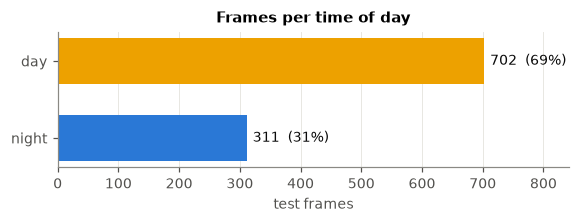

In [4]:
frames = {t: sum(c["n_frames"] for c in by_tod[t]) for t in TOD}
total = sum(frames.values())
md_table(["", "frames", "share", "clips (all lengths)"],
         [[t, frames[t], f"{frames[t] / total:.1%}", len(by_tod[t])] for t in TOD]
         + [["**total**", total, "100%", len(clips)]])

fig, ax = plt.subplots(figsize=(6, 1.6))
for y, t in enumerate(TOD):
    ax.barh(y, frames[t], color=TOD_COLOR[t], height=0.6)
    ax.text(frames[t] + total * 0.01, y, f"{frames[t]}  ({frames[t] / total:.0%})", va="center", color=INK)
ax.set_yticks(range(len(TOD)), TOD)
ax.invert_yaxis()
ax.set_xlim(0, max(frames.values()) * 1.2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("test frames")
ax.set_title("Frames per time of day")
plt.show()

## 2. Clips with more than 5 frames

In [5]:
rows = []
for t in TOD:
    kept = int(dur[t].sum())
    rows.append([t, len(by_tod[t]), f"**{len(long[t])}**", len(by_tod[t]) - len(long[t]), kept,
                 f"{kept / frames[t]:.1%}"])
n_long, kept_all = sum(len(long[t]) for t in TOD), sum(int(dur[t].sum()) for t in TOD)
rows.append(["**total**", len(clips), f"**{n_long}**", len(clips) - n_long, kept_all, f"{kept_all / total:.1%}"])
md_table(["", "clips (all)", f"clips > {MIN_FRAMES} frames", f"clips ≤ {MIN_FRAMES}",
          f"frames in clips > {MIN_FRAMES}", "share of frames kept"], rows)

|  | clips (all) | clips > 5 frames | clips ≤ 5 | frames in clips > 5 | share of frames kept |
|---|---|---|---|---|---|
| day | 91 | **46** | 45 | 621 | 88.5% |
| night | 67 | **13** | 54 | 224 | 72.0% |
| **total** | 158 | **59** | 99 | 845 | 83.4% |

## 3. Duration of clips with more than 5 frames

One panel per time of day, same bins and same axes so the two compare directly. Bins are 5 frames wide (6-10, 11-15,
...); the dashed line is the median.

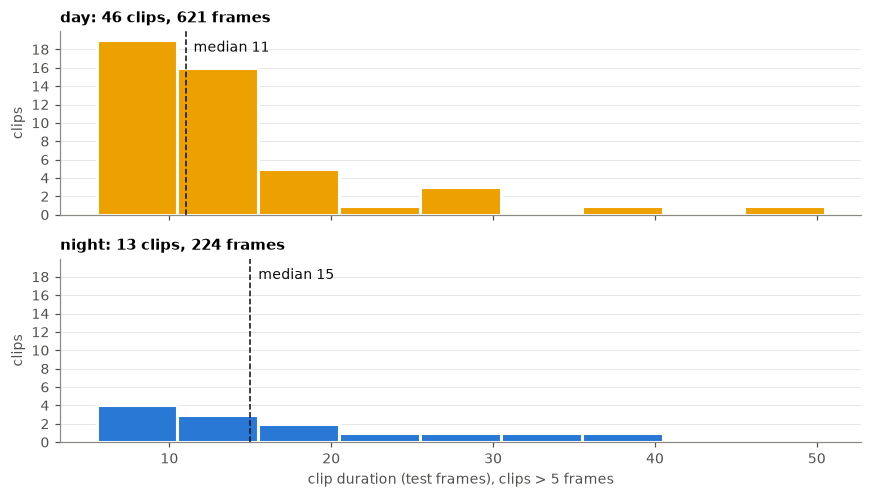

|  | clips | min | p25 | median | p75 | max | mean |
|---|---|---|---|---|---|---|---|
| day | 46 | 6 | 8.0 | 11.0 | 15.0 | 48 | 13.5 |
| night | 13 | 6 | 7.0 | 15.0 | 22.0 | 36 | 17.2 |

In [6]:
top = max(int(d.max()) for d in dur.values() if len(d))
edges = np.arange(MIN_FRAMES + 1, top + 6, 5) - 0.5
fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True, sharey=True)
for ax, t in zip(axes, TOD):
    d = dur[t]
    ax.hist(d, bins=edges, color=TOD_COLOR[t], edgecolor="white", linewidth=2)
    ax.set_title(f"{t}: {len(d)} clips, {int(d.sum())} frames", loc="left")
    ax.set_ylabel("clips")
    ax.grid(axis="x", visible=False)
axes[0].yaxis.set_major_locator(plt.MaxNLocator(integer=True))
for ax, t in zip(axes, TOD):  # after sharey has settled the limits
    if len(dur[t]):
        m = np.median(dur[t])
        ax.axvline(m, color=INK, ls="--", lw=1)
        ax.text(m, ax.get_ylim()[1] * 0.95, f"  median {m:.0f}", color=INK, va="top")
axes[-1].set_xlabel(f"clip duration (test frames), clips > {MIN_FRAMES} frames")
fig.tight_layout()
plt.show()

md_table(["", "clips", "min", "p25", "median", "p75", "max", "mean"],
         [[t, len(dur[t]), dur[t].min(), *np.percentile(dur[t], [25, 50, 75]).round(1), dur[t].max(),
           round(dur[t].mean(), 1)] for t in TOD if len(dur[t])])

### Clip list (> 5 frames)

In [7]:
md_table(["#", "start_id", "end_id", "time of day", "frames", "id span"],
         [[k, f"{c['start_id']:05d}", f"{c['end_id']:05d}", c["time_of_day"], c["n_frames"],
           c["end_id"] - c["start_id"] + 1]
          for k, c in enumerate(sorted(long["day"] + long["night"], key=lambda c: c["start_id"]), 1)])

| # | start_id | end_id | time of day | frames | id span |
|---|---|---|---|---|---|
| 1 | 08864 | 08898 | night | 33 | 35 |
| 2 | 08905 | 08925 | night | 18 | 21 |
| 3 | 08926 | 08938 | night | 13 | 13 |
| 4 | 08999 | 09009 | night | 6 | 11 |
| 5 | 09019 | 09044 | day | 18 | 26 |
| 6 | 09048 | 09055 | day | 6 | 8 |
| 7 | 09057 | 09098 | day | 37 | 42 |
| 8 | 09103 | 09113 | day | 8 | 11 |
| 9 | 09114 | 09126 | day | 10 | 13 |
| 10 | 09129 | 09134 | day | 6 | 6 |
| 11 | 09135 | 09145 | day | 11 | 11 |
| 12 | 09146 | 09155 | day | 7 | 10 |
| 13 | 09163 | 09172 | day | 9 | 10 |
| 14 | 09188 | 09194 | day | 7 | 7 |
| 15 | 09198 | 09211 | day | 13 | 14 |
| 16 | 09212 | 09233 | day | 16 | 22 |
| 17 | 09240 | 09246 | day | 6 | 7 |
| 18 | 09247 | 09257 | day | 11 | 11 |
| 19 | 09258 | 09269 | day | 12 | 12 |
| 20 | 09270 | 09283 | day | 10 | 14 |
| 21 | 09289 | 09303 | day | 15 | 15 |
| 22 | 09304 | 09313 | day | 8 | 10 |
| 23 | 09326 | 09359 | night | 28 | 34 |
| 24 | 09392 | 09398 | night | 7 | 7 |
| 25 | 09402 | 09417 | night | 15 | 16 |
| 26 | 09474 | 09497 | night | 20 | 24 |
| 27 | 09548 | 09553 | night | 6 | 6 |
| 28 | 09562 | 09568 | night | 7 | 7 |
| 29 | 09576 | 09615 | night | 36 | 40 |
| 30 | 09616 | 09637 | night | 22 | 22 |
| 31 | 09638 | 09650 | night | 13 | 13 |
| 32 | 09672 | 09685 | day | 13 | 14 |
| 33 | 09686 | 09711 | day | 26 | 26 |
| 34 | 09718 | 09739 | day | 22 | 22 |
| 35 | 09743 | 09750 | day | 8 | 8 |
| 36 | 09751 | 09757 | day | 7 | 7 |
| 37 | 09761 | 09775 | day | 15 | 15 |
| 38 | 09780 | 09785 | day | 6 | 6 |
| 39 | 09793 | 09807 | day | 15 | 15 |
| 40 | 09808 | 09815 | day | 8 | 8 |
| 41 | 09821 | 09837 | day | 17 | 17 |
| 42 | 09849 | 09855 | day | 7 | 7 |
| 43 | 09868 | 09879 | day | 11 | 12 |
| 44 | 09888 | 09907 | day | 11 | 20 |
| 45 | 09912 | 09919 | day | 6 | 8 |
| 46 | 09920 | 09971 | day | 48 | 52 |
| 47 | 09977 | 10004 | day | 26 | 28 |
| 48 | 10020 | 10037 | day | 14 | 18 |
| 49 | 10038 | 10057 | day | 18 | 20 |
| 50 | 10070 | 10098 | day | 29 | 29 |
| 51 | 10099 | 10109 | day | 11 | 11 |
| 52 | 10111 | 10116 | day | 6 | 6 |
| 53 | 10117 | 10125 | day | 9 | 9 |
| 54 | 10128 | 10139 | day | 12 | 12 |
| 55 | 10140 | 10150 | day | 11 | 11 |
| 56 | 10156 | 10168 | day | 13 | 13 |
| 57 | 10174 | 10182 | day | 9 | 9 |
| 58 | 10186 | 10204 | day | 19 | 19 |
| 59 | 10207 | 10220 | day | 14 | 14 |

## 4. Random day and night frames

Five RGB frames drawn at random (without replacement) from all day frames, and five from all night frames (any clip
length), with the ground-truth boxes as in the review videos (person red, car blue). Re-run the cell to draw new
frames; set `SEED` to an int to make the draw repeatable.

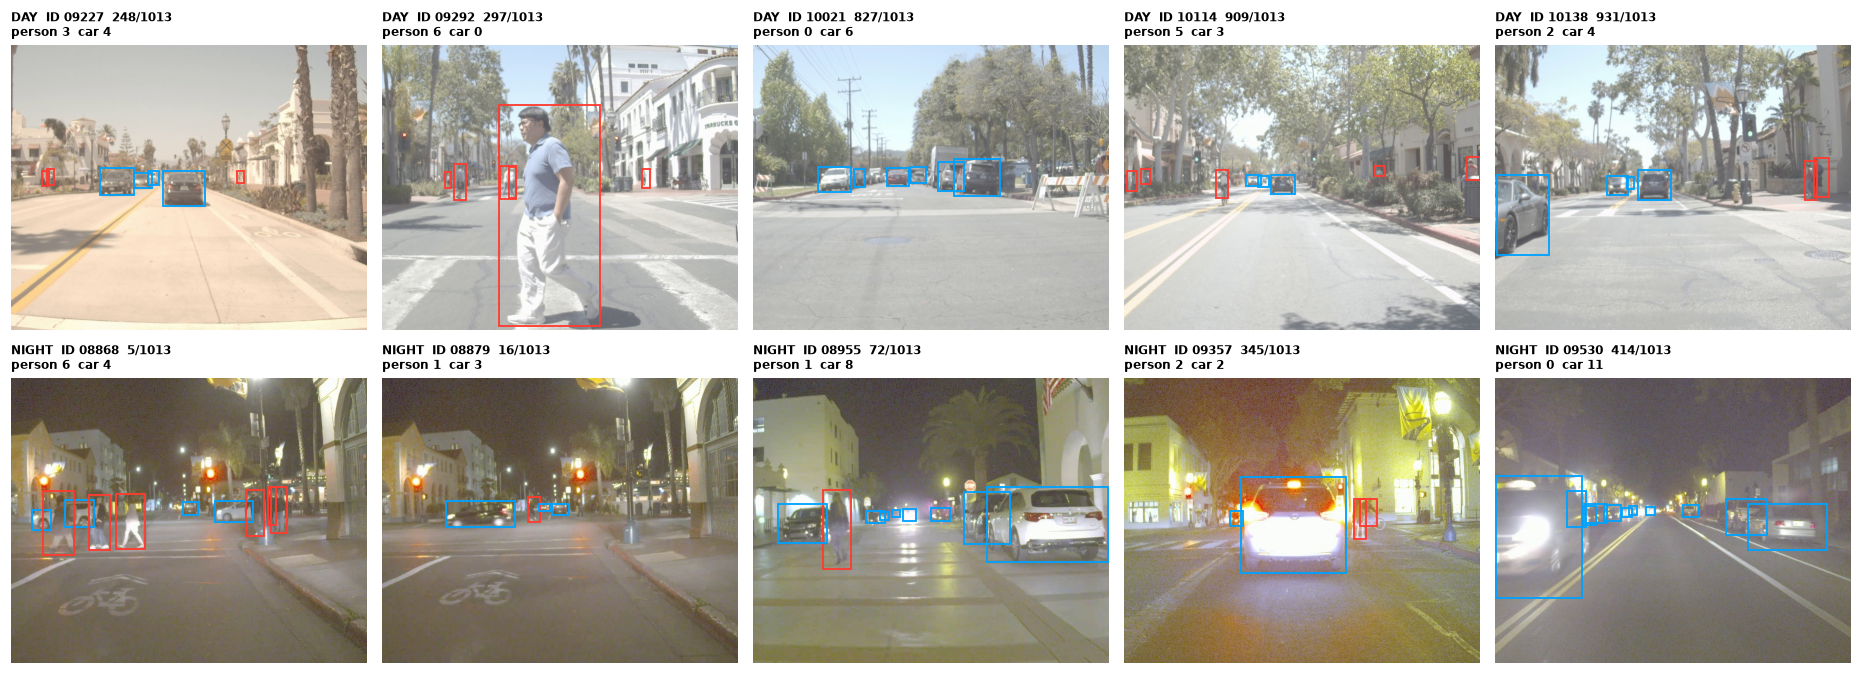

In [19]:
from matplotlib.patches import Rectangle
from PIL import Image

from irwm.data.aligned import ALIGNED_CLASS_NAMES, AlignedSplit

SEED = None  # an int makes the draw repeatable
N_PER_TOD = 5
BOX_COLOR = {0: "#ff3b30", 1: "#00a2ff"}  # person, car
rng = np.random.default_rng(SEED)
rgb = AlignedSplit.load("rgb", "test")
test_ids = rgb.image_ids()
tod_ids = {t: np.concatenate([test_ids[(test_ids >= c["start_id"]) & (test_ids <= c["end_id"])] for c in by_tod[t]])
           for t in TOD}
assert sum(len(v) for v in tod_ids.values()) == len(test_ids)
pick = {t: np.sort(rng.choice(tod_ids[t], size=N_PER_TOD, replace=False)) for t in TOD}

fig, axes = plt.subplots(len(TOD), N_PER_TOD, figsize=(3.4 * N_PER_TOD, 3.2 * len(TOD)))
for row, t in zip(axes, TOD):
    for ax, i in zip(row, pick[t]):
        r = rgb.by_image_id(int(i))
        with Image.open(r.path) as im:
            ax.imshow(np.asarray(im))
        for (x, y, w, h), lab in zip(r.boxes, r.labels):
            ax.add_patch(Rectangle((x, y), w, h, fill=False, ec=BOX_COLOR[int(lab)], lw=1.2))
        npers, ncar = int((r.labels == 0).sum()), int((r.labels == 1).sum())
        k = int(np.searchsorted(test_ids, i)) + 1
        ax.set_title(f"{t.upper()}  ID {i:05d}  {k}/{len(test_ids)}\nperson {npers}  car {ncar}",
                     loc="left", fontsize=8)
        ax.set_axis_off()
fig.tight_layout()
plt.show()